In [2]:
# 1. Загрузка данных и первичный анализ

# Импортируем нужные библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Загружаем данные
df = pd.read_csv('price_sample.csv')

# Просматриваем первые 5 строк данных
df.head()


,para1,para2,para3,para4,price
0,1,662.0,3000.0,3.8,73.49
1,1,340.0,2760.0,9.2,300.00
2,0,16.0,2700.0,3.0,130.00
3,1,17.0,12320.0,6.4,365.00
4,1,610.0,2117.0,10.8,357.50


In [3]:
# 2. Структура данных

# Получаем информацию о типах данных и пропущенных значениях
df.info()

# Статистика по данным
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   para1   10003 non-null  int64  
 1   para2   9997 non-null   float64
 2   para3   10003 non-null  float64
 3   para4   9998 non-null   float64
 4   price   10003 non-null  float64
dtypes: float64(4), int64(1)
memory usage: 390.9 KB


,para1,para2,para3,para4,price
count,10003.000000,9997.000000,10003.000000,9998.000000,10003.000000
mean,1.380986,447.270681,9547.975527,8.458024,433.774924
std,3.500408,220.913801,8022.286943,4.613645,277.443154
min,0.000000,16.000000,200.000000,1.000000,50.730000
25%,1.000000,301.000000,2899.500000,4.000000,250.000000
50%,1.000000,434.000000,6446.000000,7.200000,370.000000
75%,1.000000,582.000000,15000.000000,13.600000,550.000000
max,337.000000,2554.000000,34782.000000,27.200000,5700.000000


para1    0
para2    6
para3    0
para4    5
price    0
dtype: int64


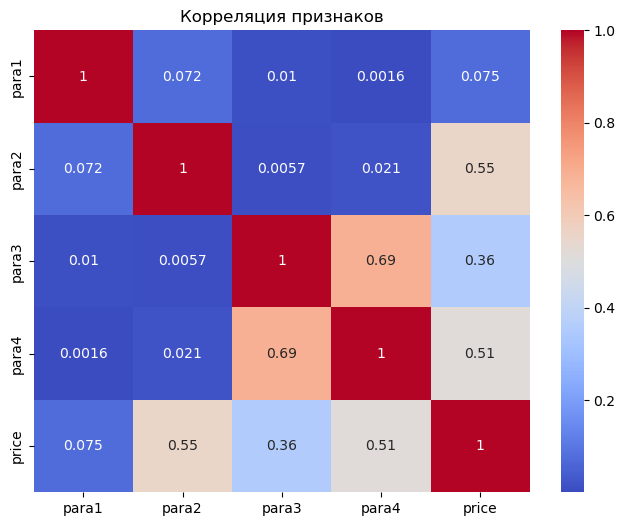

In [4]:
# 3. Проверка на пропуски и корреляция

# Проверяем наличие пропусков
print(df.isnull().sum())

# Смотрим корреляцию признаков с целевой переменной
corr_matrix = df.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Корреляция признаков')
plt.show()


In [5]:
# 4. Разделение данных

# Выделяем признаки (X) и целевую переменную (y)
X = df.drop('price', axis=1)
y = df['price']

# Делим данные на обучающую и тестовую выборки (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [11]:
# Проверяем наличие пропущенных значений
print(df.isnull().sum())

# Заполняем пропуски средним значением по каждому столбцу
df.fillna(df.mean(), inplace=True)

# После заполнения заново делим данные
X = df.drop('price', axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)




para1    0
para2    0
para3    0
para4    0
price    0
dtype: int64


In [13]:
# 5. Построение модели (Линейная Регрессия)

# Создаем и обучаем модель
model = LinearRegression()
model.fit(X_train, y_train)

# Предсказания
y_pred = model.predict(X_test)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Оцениваем качество модели
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE (средняя абсолютная ошибка): {mae:.2f}")
print(f"MSE (среднеквадратичная ошибка): {mse:.2f}")
print(f"R^2 (коэффициент детерминации): {r2:.2f}")



MAE (средняя абсолютная ошибка): 121.07
MSE (среднеквадратичная ошибка): 39723.15
R^2 (коэффициент детерминации): 0.55


In [9]:
# 6. Оценка модели

# Вычисляем метрики качества
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'MSE: {mse:.2f}')
print(f'MAE: {mae:.2f}')
print(f'R²: {r2:.2f}')


MSE: 39723.15
MAE: 121.07
R²: 0.55
